# Example: RMDC26_000026 — a blind Roman light curve with a close planet

This example runs lenscape on a simulated light curve from the *Nancy Grace Roman Space Telescope* Galactic Bulge Time
Domain Survey, without knowing the answer. The earlier examples (`example_kb221551` and others) re-analyse published
KMTNet events and compare with the published solutions; here nothing is known in advance.

**The data.** RMDC26_000026 is event 26 of the *Beginner tier* of the Roman Microlensing Data Challenge 2026
(Roman Galactic Exoplanet Survey Project Infrastructure Team, RGES-PIT; public domain, CC0,
[huggingface.co/datasets/RGES-PIT/Beginner](https://huggingface.co/datasets/RGES-PIT/Beginner)). The light curves were
simulated with the GULLS survey simulator (Penny et al. 2019): six observing seasons of about 70 days over 4.7 years,
one exposure every 12 minutes in the wide F146 filter and one every few hours in F087 and F213. The challenge does not
publish the true parameters of its events, so this is a **blind** analysis. I chose this event from the 188 of the tier
because its whole event lies inside one season, its timescale is short (so parallax should be small), none of its points
are saturated, and it has a clear anomaly on the rising wing.

**What this notebook does.**

1. It loads the photometry (49 096 points in three filters) and looks at the event (Section 1).
2. It reduces the data to 1773 points for the maps: only the event's season, binned in time except during the anomaly,
   and checks that the binning changes no Δχ² between models (Section 2).
3. It reads the planet's separation off the anomaly time and fits close and wide models from guided starts
   (Sections 3 and 4).
4. It maps Δχ²(log *s*, log *q*) on a coarse lattice and then in two zoom boxes (Sections 5 and 6).
5. It polishes the best fit and shows the light curve, the residuals and the caustics (Sections 7–9).
6. It interprets the system: a planet of about 10⁻⁴ of its host's mass, just inside the Einstein ring (Section 10).

**Runtime.** The maps took 6.7, 12.1 and 4.7 minutes on a 14-core Intel Core i5-13500 (20 threads), the guided fits
and the polish a few minutes more. Everything is stored in `data/`, so the notebook runs in about a minute by default.
Set `RECOMPUTE = True` to compute it all again (about 30 minutes on a 20-thread desktop).

## 0. Setup

In [1]:
import os, time, json
import numpy as np
import matplotlib.pyplot as plt
import lenscape
from lenscape import figures, caustics, model

RECOMPUTE = False              # True: compute all maps and fits again (about 30 min on a 20-thread desktop)
LOGFILE = os.environ.get("LENSCAPE_LOG")          # progress of long runs is also appended here if set


def log(msg):
    print(msg, flush=True)
    if LOGFILE:
        with open(LOGFILE, "a") as f:
            f.write(f"{time.strftime('%H:%M:%S')} {msg}\n")

print("lenscape", lenscape.__version__)

lenscape 1.0


## 1. The photometry

`data/rmdc026_photometry.csv` holds all unsaturated points of the event (there are no saturated ones), converted from
the challenge's magnitudes to linear fluxes:

| column | meaning |
|---|---|
| `set` | filter: `F087`, `F146` or `F213` |
| `t` | BJD − 2460000 |
| `flux` | 10^(−0.4 (mag − 25)): flux on a zero point of 25 mag |
| `flux_err` | its error, from the challenge's magnitude error (not rescaled) |

The error bars are used as given. They turn out to be right: the best fit at the end has χ²/N = 1.0003 on all 49 096
points.

In [2]:
SETS = ["F087", "F146", "F213"]
ZP = 25.0
rows = np.genfromtxt("data/rmdc026_photometry.csv", delimiter=",", names=True, dtype=None, encoding="utf-8",
                     skip_header=3)                     # the first three lines are comments
sel = lambda r, n: (r["t"][r["set"] == n], r["flux"][r["set"] == n], r["flux_err"][r["set"] == n])
data_all = lenscape.Data.from_sets({n: sel(rows, n) for n in SETS})
mag = lambda f: ZP - 2.5 * np.log10(f)
data_all

Data(49096 points, t 1447.76 .. 3164.50, sets {'F087': 1445, 'F146': 46208, 'F213': 1443})

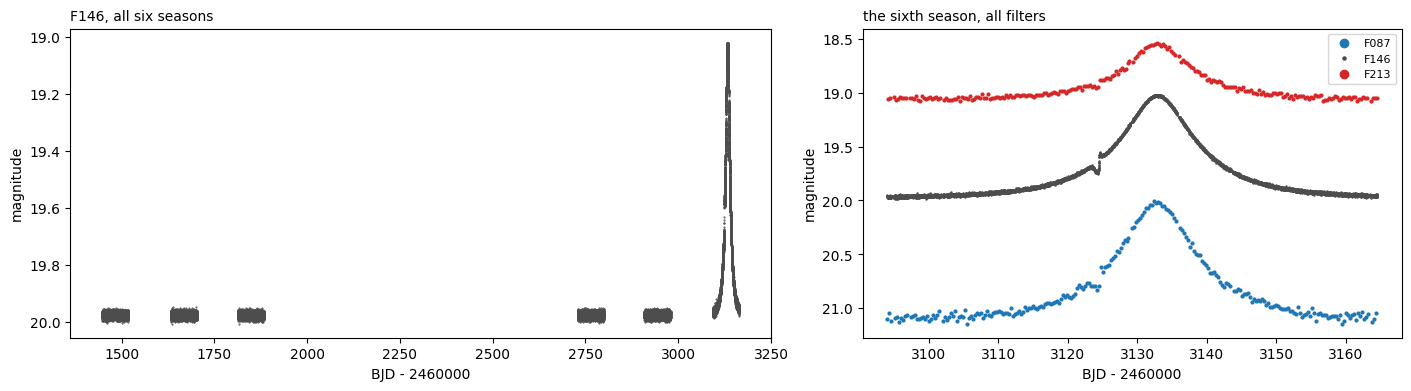

In [3]:
fig, axs = plt.subplots(1, 2, figsize=(14, 3.8), gridspec_kw=dict(width_ratios=[1.3, 1]), constrained_layout=True)
k = data_all.names.index("F146")
m = data_all.idx == k
axs[0].plot(data_all.t[m], mag(data_all.f[m]), ".", ms=1, color="0.3", rasterized=True)
axs[0].set_title("F146, all six seasons", loc="left", fontsize=10)
for j, (n, c) in enumerate(zip(SETS, ["C0", "0.3", "C3"])):
    m = (data_all.idx == j) & (data_all.t > 3094) & (data_all.t < 3165)
    axs[1].plot(data_all.t[m], mag(data_all.f[m]), ".", ms=1.5 if n == "F146" else 4, color=c, label=n, rasterized=True)
axs[1].set_title("the sixth season, all filters", loc="left", fontsize=10)
axs[1].legend(fontsize=8, markerscale=3)
for ax in axs:
    ax.invert_yaxis(); ax.set_xlabel("BJD - 2460000"); ax.set_ylabel("magnitude")

The event peaks at BJD′ ≈ 3133 (BJD′ = BJD − 2460000) in the last of the six seasons, 1.0 mag above a baseline of
F146 = 20.0. On the rising wing, nine days before the peak, the light curve first dips and then jumps up: the anomaly.
The other five seasons are flat baseline.

## 2. Reducing the data for the maps

Fitting all 49 096 points is wasteful. Five seasons are flat baseline, 30 to 130 Einstein timescales from the peak;
there lenscape needs about 20 µs per point (its root solver works hard where the images sit at the Einstein ring),
so they cost 98 % of the time of a χ² while saying nothing about the planet. Inside the season the light curve is smooth
except during the anomaly, so 12-minute sampling is far more than needed there. The map data are therefore:

* only the sixth season, BJD′ 3094–3165 (−3 to +2.5 Einstein timescales around the peak);
* F146 at full cadence during the anomaly, BJD′ 3122.5–3126.5;
* F146 in 1-hour bins within one Einstein timescale of the peak (the single-lens fit of Section 3, rounded to
  *t*₀ = 3133.0, *t*ₑ = 12.6 d), and in 3-hour bins elsewhere in the season. A bin is the error-weighted mean of its
  points, in time and flux, with error σ = (Σ σᵢ⁻²)^(−1/2);
* F087 and F213 unbinned (one point every few hours).

lenscape's own wing binning (`bin_wings`, per night) is switched off for these data: it splits runs at gaps, and a
Roman season has none.

In [4]:
SEASON = (3094.0, 3165.0)
ANOM = (3122.5, 3126.5)
T0_BIN, TE_BIN = 3133.0, 12.6


def reduce(rows):
    # season only; F146: full cadence in ANOM, 1-h bins within TE_BIN of T0_BIN, 3-h bins elsewhere
    out = {}
    for n in SETS:
        t, f, e = sel(rows, n)
        m = (t >= SEASON[0]) & (t <= SEASON[1])
        t, f, e = t[m], f[m], e[m]
        if n != "F146":
            out[n] = (t, f, e); continue
        full = (t >= ANOM[0]) & (t <= ANOM[1])
        inner = np.abs(t - T0_BIN) < TE_BIN
        width = np.where(inner, 1 / 24, 3 / 24)
        key = np.floor((t - SEASON[0]) / width).astype(int) * 2 + inner
        T, F, E = [t[full]], [f[full]], [e[full]]
        b = ~full
        u, inv = np.unique(key[b], return_inverse=True)
        w = 1 / e[b] ** 2
        W = np.bincount(inv, w)
        T.append(np.bincount(inv, w * t[b]) / W); F.append(np.bincount(inv, w * f[b]) / W); E.append(W ** -0.5)
        t, f, e = (np.concatenate(x) for x in (T, F, E))
        o = np.argsort(t)
        out[n] = (t[o], f[o], e[o])
    return lenscape.Data.from_sets(out)

data = reduce(rows)
season = data_all.window(*SEASON)
print(f"all {len(data_all)} points, season {len(season)}, binned {len(data)}:",
      {n: len(s) for n, s in zip(data.names, data.slices)})

all 49096 points, season 8152, binned 1773: {'F087': 239, 'F146': 1294, 'F213': 240}


The binned data have 1773 points, 28 times fewer than all data. One χ² costs 0.5 ms instead of 180 ms. Whether the
binning loses information is checked below with three models: the best fit of Section 7 and the two best wide
solutions of Section 4. What matters for a map is the Δχ² *between* models, and those agree with the unbinned season
data to 1 in 10 000. (The χ² itself is higher on all data, because they have six times more points.)

In [5]:
be = lenscape.make_backend(lenscape.config.REFINE_BACKEND)
best_file = "data/rmdc026_best.json"
first_file = "data/rmdc026_first_fits.json"
if os.path.exists(first_file) and os.path.exists(best_file):
    _first = json.load(open(first_file))["fits"]
    check = {"best fit": np.array(json.load(open(best_file))["p_season"]),
             "wide 1": np.array(min((f for f in _first if f[1][3] > 0), key=lambda f: f[0])[1]),
             "wide 2": np.array([f for f in _first if f[0] > 17000][0][1])}
    c = {k: [model.chi2(be, p, d) for d in (data, season, data_all)] for k, p in check.items()}
    c0 = c["best fit"]
    print(f"{'':9s} {'binned':>10s} {'season':>10s} {'all':>10s}   (Delta chi2 to the best fit)")
    for k, v in c.items():
        print(f"{k:9s} " + " ".join(f"{a - b:10.2f}" for a, b in zip(v, c0)))
    print(f"best fit: chi2 = {c0[0]:.1f} (binned, N = {len(data)}), {c0[1]:.1f} (season, N = {len(season)}), "
          f"{c0[2]:.1f} (all, N = {len(data_all)})")

              binned     season        all   (Delta chi2 to the best fit)
best fit        0.00       0.00       0.00
wide 1      10620.52   10619.58   11270.61
wide 2      15769.58   15769.45   16579.02
best fit: chi2 = 1924.5 (binned, N = 1773), 8266.8 (season, N = 8152), 49109.2 (all, N = 49096)


The binned data reproduce the season's Δχ² of the wide models (about 10 600 and 15 800) to 1.0 and 0.2. On all data the
differences grow by about 5 %, because the five baseline seasons pin the blend flux a little better; this does not
change which model is best. The best fit has χ²/N = 1.0003 on all 49 096 points, so the simulated error bars are right
and the static model (no parallax, no orbital motion) describes all six seasons.

## 3. The single-lens fit and where the planet must be

A point lens with a finite source, fitted with the anomaly masked, gives *t*₀, *u*₀ and *t*ₑ. The anomaly lies at
τ = (*t* − *t*₀)/*t*ₑ ≈ −0.66, where the source is *u* = √(*u*₀² + τ²) ≈ 0.73 Einstein radii from the host. A planet
perturbs the light curve where the source passes close to one of its *planetary caustics*, which lie at
|*s* − 1/*s*| from the host along the binary axis. So *s* − 1/*s* = ±0.73: **s ≈ 1.43 (wide) or s ≈ 0.70 (close)**.
The short dip before the jump suggests the close case: a close planet produces two small triangular caustics with a
demagnified region between them (Gaudi 2012, Fig. 5).

In [6]:
first = json.load(open(first_file)) if os.path.exists(first_file) and not RECOMPUTE else None
if first is None:
    log("computing the guided fits")
    from scipy.optimize import minimize
    m = data.select(~((data.t >= ANOM[0]) & (data.t <= ANOM[1])))
    def c2_single(x):
        A = lenscape.single.lc_1l1s(x[0], x[1], abs(x[2]) + 1e-3, 10 ** min(x[3], -0.5), m.t, 0.0)
        return model.chi2_profiled(A, m.f, m.w, m.idx, m.nsets)
    r = min((minimize(c2_single, [3133.0, u0, tE, -3.0], method="Nelder-Mead", options=dict(maxfev=4000, adaptive=True))
             for u0 in (0.1, 0.3, 0.6) for tE in (5.0, 12.0, 25.0)), key=lambda r: r.fun)
    sl = dict(t0=float(r.x[0]), u0=abs(float(r.x[1])), tE=abs(float(r.x[2])) + 1e-3)
    tau_a = (np.mean(ANOM) - sl["t0"]) / sl["tE"]
    ua = float(np.hypot(sl["u0"], tau_a))
    s_w = (ua + np.sqrt(ua ** 2 + 4)) / 2
    grid = lenscape.make_backend(lenscape.config.GRID_BACKEND)
    trials = []                     # 360 angles at each (s, q, rho) at the single-lens trajectory (u0 > 0 suffices)
    for s in (s_w, 1 / s_w):
        for lq in np.arange(-4.5, -1.4, 0.5):
            for lr in (-3.5, -3.0, -2.5):
                for a in np.arange(360) * 2 * np.pi / 360:
                    p = [sl["t0"], sl["u0"], sl["tE"], float(np.log10(s)), float(lq), float(a), lr]
                    trials.append((model.chi2(grid, p, data), p))
    trials.sort(key=lambda r: r[0])
    starts = []
    for c, p in trials:                                   # the 16 best, distinct in (s, q, alpha)
        if all(abs(p[3] - q[3]) > 1e-3 or abs(p[4] - q[4]) > 1e-3 or abs(np.angle(np.exp(1j * (p[5] - q[5])))) > 0.15
               for _, q in starts):
            starts.append((c, p))
        if len(starts) == 16:
            break
    fits = []
    for _, p in starts:
        c, p = lenscape.fit_full(data, p, grid, rounds=2, maxfev=3000)
        c, p = lenscape.fit_full(data, p, be, rounds=2, maxfev=3000)
        fits.append((float(c), [float(v) for v in p]))
    first = dict(single_lens=sl, tau_anomaly=tau_a, u_anomaly=ua, s_wide_predicted=s_w,
                 fits=sorted(fits, key=lambda f: f[0]))
    json.dump(first, open(first_file, "w"), indent=1)
sl = first["single_lens"]
print(f"single lens (anomaly masked): t0 = {sl['t0']:.3f}, u0 = {sl['u0']:.3f}, tE = {sl['tE']:.2f} d")
print(f"anomaly at tau = {first['tau_anomaly']:.3f}, u = {first['u_anomaly']:.3f} -> s = "
      f"{first['s_wide_predicted']:.3f} (wide) or {1 / first['s_wide_predicted']:.3f} (close)")

single lens (anomaly masked): t0 = 3132.858, u0 = 0.314, tE = 12.63 d
anomaly at tau = -0.662, u = 0.733 -> s = 1.431 (wide) or 0.699 (close)


## 4. Guided fits: close against wide

At each predicted *s*, every log *q* from −4.5 to −1.5 (steps of 0.5) and three source sizes (log ρ = −3.5, −3, −2.5),
360 trajectory angles are tried at the single-lens trajectory. The 16 best distinct starts are fitted in all seven
parameters (`lenscape.fit_full`). This takes 3 minutes on 20 cores (the stored results were computed in parallel and
also include the offset-degenerate partner of each solution, `lenscape.fit.offset_partner`, which always fell back
onto one of the solutions below).

In [7]:
print(f"{'chi2':>9s} {'log s':>8s} {'log q':>7s} {'alpha':>6s} {'u0':>7s} {'tE':>7s} {'log rho':>7s}")
shown = []
for c, p in first["fits"]:
    if all(abs(c - c2) > 0.5 or abs(p[3] - p2[3]) > 1e-3 for c2, p2 in shown):
        shown.append((c, p))
        print(f"{c:9.2f} {p[3]:+8.4f} {p[4]:+7.3f} {p[5] % (2 * np.pi):6.3f} {p[1]:+7.4f} {p[2]:7.3f} {p[6]:+7.3f}")
best_first = np.array(first["fits"][0][1])

     chi2    log s   log q  alpha      u0      tE log rho
  1924.43  -0.1571  -3.937  3.562 +0.3123  12.683  -2.602
 12544.97  +0.1687  -4.083  0.457 +0.3291  12.109  -5.000
 12547.45  +0.1687  -4.083  0.457 +0.3291  12.110  -3.189
 12548.50  +0.1697  -4.073  0.458 +0.3317  12.043  -4.999
 12857.17  +0.1680  -4.005  0.460 +0.3271  12.158  -2.064
 17694.04  +0.1704  -3.810  0.376 +0.3366  11.945  -2.699
 17706.37  +0.1711  -3.750  0.369 +0.3370  11.940  -1.649
 17707.44  +0.1719  -3.728  0.368 +0.3387  11.898  -1.607
 18555.73  +0.1872  -2.696  0.222 +0.3497  11.814  -0.880
 19997.32  +0.1944  -1.736  6.233 +0.3246  12.707  -2.178
 20609.77  -0.2596  -3.455  5.077 +0.3244  12.249  -2.186


The close model fits (χ² = 1924 for 1773 points); the best wide model is 10 600 worse, and none of the others comes
close. The best fit has *s* = 0.70 and *q* = 1.2 × 10⁻⁴. The map checks whether a better solution exists anywhere else.

## 5. The coarse map

The lattice covers log *s* from −0.4 to +0.4 (*s* = 0.40 to 2.5, both predicted separations with a wide margin) in
steps of 0.04 and log *q* from −5 to −1 in steps of 0.1: 21 × 41 = 861 points. `lenscape.lattice` runs its five stages
(seed grid, cell fits, lattice-point fits, neighbour refinement, outlier recalculation; `06_maps` explains them) from
the guided best fit. Points more than 500 above the minimum are not refined (`dchi2_cut=5`), which is safe here: the
single-lens model is 19 000 worse, so almost the whole map is far above the minimum. **Runtime: 6.7 minutes**
(20 threads).

In [8]:
KEYS = ("logs", "logq", "chi2", "pars", "chi2_ref", "wall")


def run_or_load(name, compute):
    # data/rmdc026_map_NAME.npz: computed (and saved) if missing or RECOMPUTE, else loaded
    path = f"data/rmdc026_map_{name}.npz"
    if RECOMPUTE or not os.path.exists(path):
        log(f"computing map {name}")
        m = compute()
        np.savez_compressed(path, **{k: m[k] for k in KEYS})
        log(f"map {name}: {m['chi2'].shape}, {m['wall'] / 60:.1f} min, lowest chi2 {np.nanmin(m['chi2']):.2f}")
        return m
    return dict(np.load(path))

logs1 = np.round(np.arange(-0.4, 0.4001, 0.04), 4)
logq1 = np.round(np.arange(-5.0, -0.9999, 0.1), 4)
map1 = run_or_load("1x", lambda: lenscape.lattice(data, logs1, logq1, best=best_first, bin_wings=False, dchi2_cut=5.0,
                                                  log=log))
print(f"{map1['chi2'].shape} points, wall time {map1['wall'] / 60:.1f} min, lowest point {np.nanmin(map1['chi2']):.2f}")

(21, 41) points, wall time 6.7 min, lowest point 1970.78


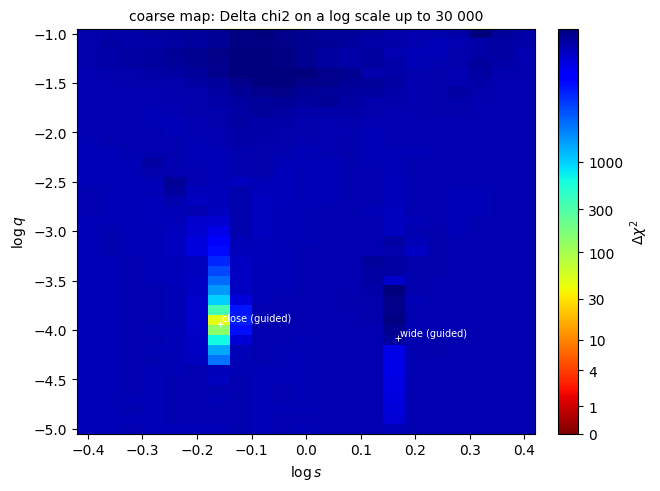

In [9]:
fig, ax = plt.subplots(figsize=(6.5, 4.8), constrained_layout=True)
ref1 = min(np.nanmin(map1["chi2"]), first["fits"][0][0])
figures.plot_map(map1, ax=ax, vmax=30000, chi2_ref=ref1,
                 marks={"close (guided)": best_first[3:5],
                        "wide (guided)": min((f for f in first["fits"] if f[1][3] > 0), key=lambda f: f[0])[1][3:5]})
ax.set_title("coarse map: Delta chi2 on a log scale up to 30 000", fontsize=10);

There is one valley, at log *s* ≈ −0.16 and log *q* between about −4.3 and −3.2, around the guided close solution.
The faint stripe at log *s* ≈ +0.17 is the wide solution, about 10 000 above it; everything else is higher still. But the valley is far narrower than the
lattice: its best lattice point is 47 above the best fit, and only that one point is within Δχ² < 100.

## 6. Zooming in

`lenscape.maps.densify` fits every point of a finer lattice from the nearest known solutions, then runs the neighbour
and outlier stages. Two boxes, both aligned with the coarse lattice:

* **8×:** log *s* from −0.24 to −0.08 at 1/8 of the coarse step (0.005), log *q* from −4.5 to −3.3 at 1/4 (0.025):
  33 × 49 points, **12.1 minutes**. Its lowest point is still 18.8 above the minimum.
* **64×:** log *s* from −0.163 to −0.150 at 1/64 of the coarse step (0.000625), log *q* from −4.1 to −3.8 at 1/8 (0.0125):
  21 × 25 points, **4.7 minutes**.

In [10]:
step = lambda lo, hi, x0, st: np.round(x0 + st * np.arange(int(np.ceil((lo - x0) / st - 1e-9)),
                                                           int(np.floor((hi - x0) / st + 1e-9)) + 1), 6)
map8 = run_or_load("box_8x", lambda: lenscape.maps.densify(
    [map1], data, step(-0.24, -0.08, -0.4, 0.005), step(-4.5, -3.3, -5.0, 0.025), best=best_first, bin_wings=False,
    log=log))
map64 = run_or_load("box_64x", lambda: lenscape.maps.densify(
    [map8, map1], data, step(-0.163, -0.150, -0.4, 0.000625), step(-4.1, -3.8, -5.0, 0.0125), best=best_first,
    bin_wings=False, log=log))
MAPS = [("coarse", map1), ("8x box", map8), ("64x box", map64)]
ref = min(np.nanmin(m["chi2"]) for _, m in MAPS)
for name, m in MAPS:
    i, j = np.unravel_index(np.nanargmin(m["chi2"]), m["chi2"].shape)
    print(f"{name:8s}: {m['chi2'].shape[0]:2d} x {m['chi2'].shape[1]:2d} points, {m['wall'] / 60:4.1f} min, lowest "
          f"point {m['chi2'][i, j] - ref:6.2f} above the minimum at log s = {m['logs'][i]:.5f}, log q = {m['logq'][j]:.4f}")

coarse  : 21 x 41 points,  6.7 min, lowest point  47.28 above the minimum at log s = -0.16000, log q = -3.9000
8x box  : 33 x 49 points, 12.1 min, lowest point  18.83 above the minimum at log s = -0.15500, log q = -3.9500
64x box : 21 x 25 points,  4.7 min, lowest point   0.00 above the minimum at log s = -0.15687, log q = -3.9375


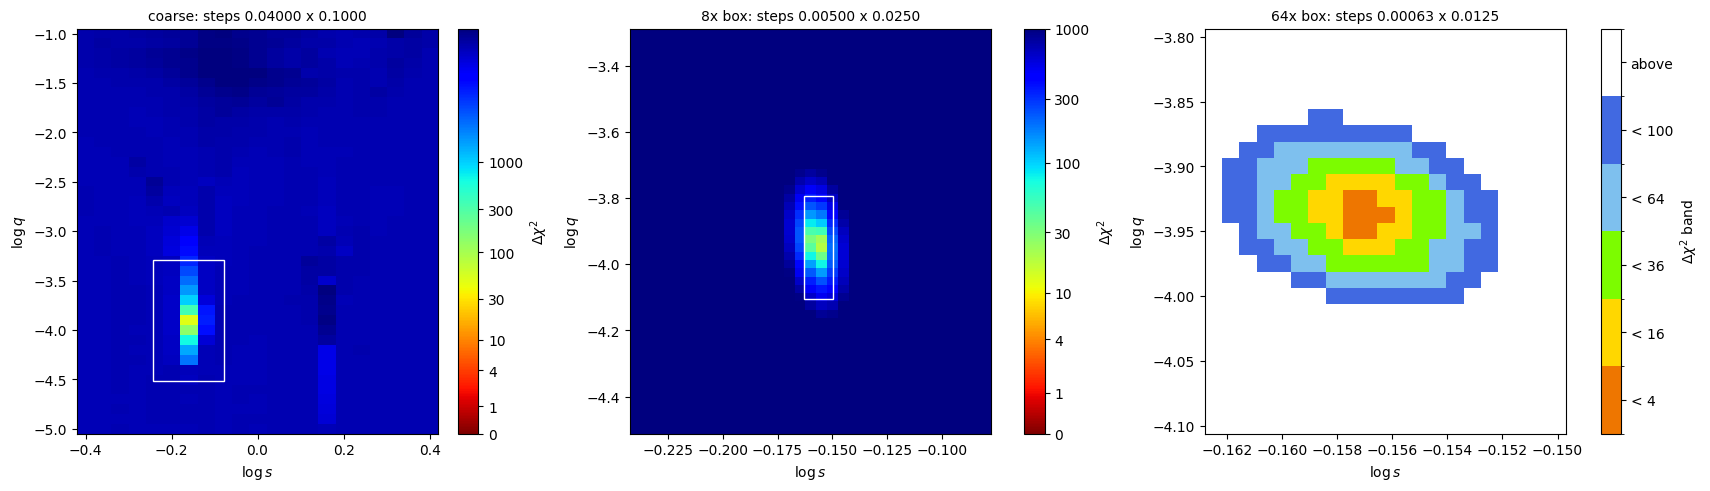

In [11]:
fig, axs = plt.subplots(1, 3, figsize=(17, 4.8), constrained_layout=True)
figures.plot_map(map1, ax=axs[0], vmax=30000, chi2_ref=ref)
figures.plot_map(map8, ax=axs[1], vmax=1000, chi2_ref=ref)
figures.plot_map(map64, bands=(4, 16, 36, 64, 100), ax=axs[2], chi2_ref=ref)
for ax, (_, m), c in zip(axs[:2], MAPS[1:], ("w", "w")):        # outline of the next box
    hs, hq = (m["logs"][1] - m["logs"][0]) / 2, (m["logq"][1] - m["logq"][0]) / 2
    ax.add_patch(plt.Rectangle((m["logs"][0] - hs, m["logq"][0] - hq), m["logs"][-1] - m["logs"][0] + 2 * hs,
                               m["logq"][-1] - m["logq"][0] + 2 * hq, fill=False, ec=c, lw=1))
for ax, (name, m) in zip(axs, MAPS):
    ax.set_title(f"{name}: steps {m['logs'][1] - m['logs'][0]:.5f} x {m['logq'][1] - m['logq'][0]:.4f}", fontsize=10)

The coarse map and the 8× box use a logarithmic colour scale (up to 30 000 and 1000), the 64× box the usual
bands. At 64× the minimum is resolved: a single closed, slightly tilted ellipse. Its Δχ² < 4 region spans only 0.0012 dex in
log *s* and 0.025 dex in log *q*; Δχ² < 100 spans ±0.005 dex in log *s* and ±0.07 dex in log *q*. The separation is
measured to about 0.1 % and the mass ratio to about 3 %, far better than for the KMTNet examples. Roman's 12-minute
cadence and 1 % photometry resolve the anomaly in detail, so a planet that would leave a broad valley in ground-based
data leaves a sharp point here. That is also why the coarse map, with steps 30 times wider than the valley, could
not show the minimum.

There is no second minimum: the 8× box covers ±0.08 dex in log *s* and ±0.6 dex in log *q* around the valley,
everything else on the coarse map is at least 1000 worse, and the wide model is 10 600 worse.

## 7. The best fit

The lowest point of the 64× map is polished with all seven parameters free (`lenscape.fit_full`, precise backend), first
on the binned data, then on the unbinned season data.

In [12]:
if RECOMPUTE or not os.path.exists(best_file):
    log("polishing the best fit")
    i, j = np.unravel_index(np.nanargmin(map64["chi2"]), map64["chi2"].shape)
    x = map64["pars"][i, j]
    p0 = np.array([x[0], x[1], x[2], map64["logs"][i], map64["logq"][j], x[3], x[4]])
    c_b, p_b = min((lenscape.fit_full(data, p, be) for p in (p0, best_first)), key=lambda r: r[0])
    c_s, p_s = lenscape.fit_full(season, p_b, be, rounds=2, maxfev=4000)
    json.dump(dict(p_binned=list(p_b), p_season=list(p_s)), open(best_file, "w"), indent=1)
B = json.load(open(best_file))
best = np.array(B["p_season"])
for name, p in (("binned data", np.array(B["p_binned"])), ("season data", best)):
    print(f"fit on the {name}: t0 = {p[0]:.4f}, u0 = {p[1]:.5f}, tE = {p[2]:.3f} d, s = {10 ** p[3]:.5f}, "
          f"q = {10 ** p[4] * 1e4:.4f}e-4, alpha = {p[5]:.4f}, rho = {10 ** p[6] * 1e3:.3f}e-3")
r = model.residuals(be, best, season)
for k, n in enumerate(season.names):
    print(f"  {n}: chi2 / N = {np.sum(r[season.idx == k] ** 2):.1f} / {np.sum(season.idx == k)}")
fs, fb = model.fluxes(model.magnification(be, best, season), season)
for k, n in enumerate(season.names):
    print(f"  {n}: source {mag(fs[k]):.3f} mag, blend {mag(fb[k]):.3f} mag, source fraction {fs[k] / (fs[k] + fb[k]):.2f}")

fit on the binned data: t0 = 3132.8605, u0 = 0.31234, tE = 12.683 d, s = 0.69654, q = 1.1563e-4, alpha = 3.5616, rho = 2.500e-3
fit on the season data: t0 = 3132.8605, u0 = 0.31232, tE = 12.683 d, s = 0.69654, q = 1.1555e-4, alpha = 3.5616, rho = 2.401e-3
  F087: chi2 / N = 203.7 / 239
  F146: chi2 / N = 7754.9 / 7673
  F213: chi2 / N = 308.2 / 240
  F087: source 21.420 mag, blend 22.624 mag, source fraction 0.75
  F146: source 20.525 mag, blend 20.979 mag, source fraction 0.60
  F213: source 20.520 mag, blend 19.393 mag, source fraction 0.26


The fits on the binned and on the unbinned data agree to better than their sensitivity in every parameter except
the source size, which differs by 4 %; the binned data average away part of the finite-source signal of the
cusp passage. The season fit is the one to quote:

| parameter | value |
|---|---|
| *t*₀ (BJD′) | 3132.861 |
| *u*₀ | 0.3123 |
| *t*ₑ | 12.68 d |
| *s* | 0.6965 |
| *q* | 1.156 × 10⁻⁴ |
| α | 3.562 rad |
| ρ | 2.40 × 10⁻³ |

(No uncertainties yet: they need an MCMC, `08_mcmc`; the map gives a first idea, ±0.0006 in log *s* and ±0.012 in log *q*
at Δχ² = 1.) F146 and F087 have χ²/N = 1.01 and 0.85; F213 has 1.28, which may point to limb darkening (the fit uses a
uniform source) or to the error bars of that filter. Of the F146 baseline flux, 60 % is the source; the rest is blended
light (in these simulations it includes the lens and unrelated stars).

## 8. The light curve

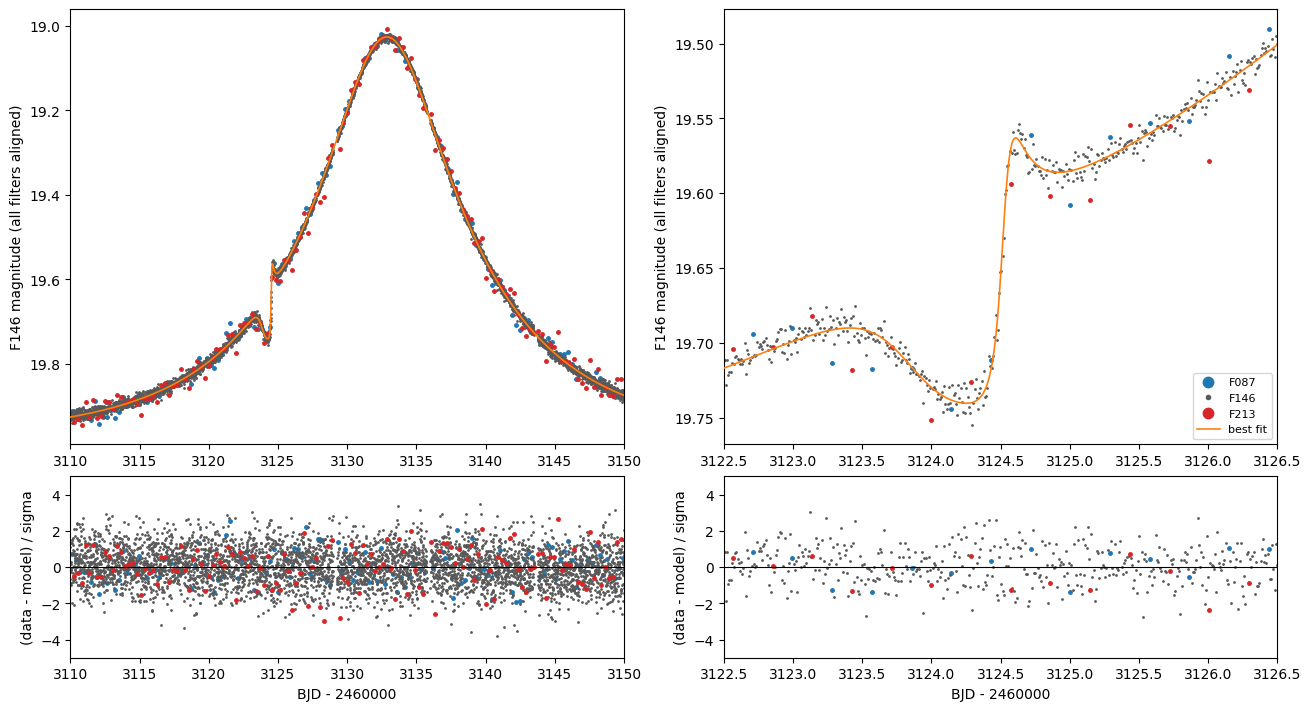

In [13]:
def plot_lc(p, d=season, window=(3110, 3150), zoom=(3122.5, 3126.5)):
    # F146 and the other filters aligned to the F146 scale of the model p; residuals of the unbinned season data
    fs, fb = model.fluxes(model.magnification(be, p, d), d)
    k0 = d.names.index("F146")
    fig = plt.figure(figsize=(13, 7), constrained_layout=True)
    gs = fig.add_gridspec(2, 2, height_ratios=[2.4, 1])
    for col, (a, b) in enumerate((window, zoom)):
        ax, axr = fig.add_subplot(gs[0, col]), fig.add_subplot(gs[1, col])
        for k, (n, c) in enumerate(zip(d.names, ["C0", "0.35", "C3"])):
            m = (d.idx == k) & (d.t > a) & (d.t < b)
            A = (d.f[m] - fb[k]) / fs[k]                            # magnification implied by each point
            ax.plot(d.t[m], mag(fs[k0] * A + fb[k0]), ".", ms=2 if n == "F146" else 5, color=c, label=n, zorder=2)
            res = model.residuals(be, p, d)[m]
            axr.plot(d.t[m], res, ".", ms=2 if n == "F146" else 5, color=c)
        tt = np.linspace(a, b, 3000)
        Am = be.lc(model.clamp(p)[0], tt)
        ax.plot(tt, mag(fs[k0] * Am + fb[k0]), color="C1", lw=1.2, label="best fit", zorder=3)
        ax.invert_yaxis(); ax.set_xlim(a, b); ax.set_ylabel("F146 magnitude (all filters aligned)")
        axr.axhline(0, color="k", lw=0.8); axr.set_xlim(a, b); axr.set_ylim(-5, 5)
        axr.set_ylabel("(data - model) / sigma"); axr.set_xlabel("BJD - 2460000")
    ax.legend(fontsize=8, markerscale=3, loc="lower right")
    return fig

plot_lc(best);

The model follows the data through the whole anomaly (right): a gentle dip of 0.05 mag lasting a day (BJD′ 3123.4 to
3124.4), then a sharp rise by 0.1 mag within a few hours at BJD′ 3124.5, after which the light curve relaxes to the
single-lens curve within a day. The residuals are flat, in all three filters. The bluer F087 and redder F213 points
follow the F146 curve once aligned, as they should for a lens (the magnification does not depend on colour, apart from
limb darkening).

## 9. The caustics and the source trajectory

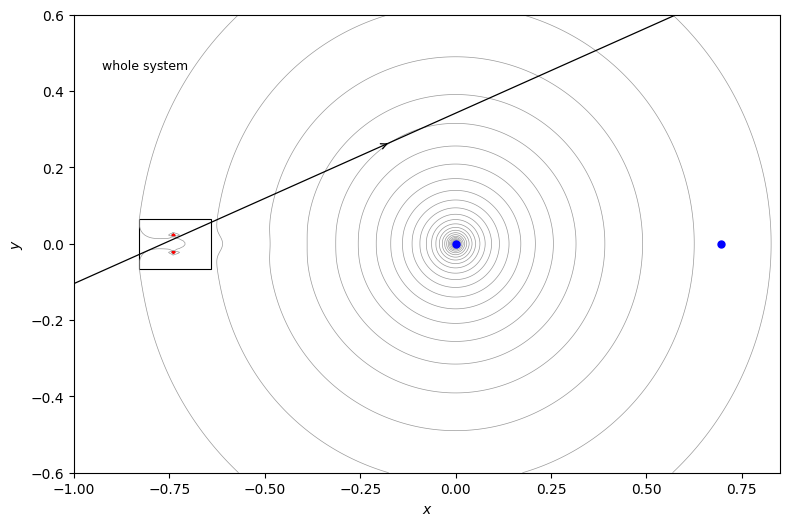

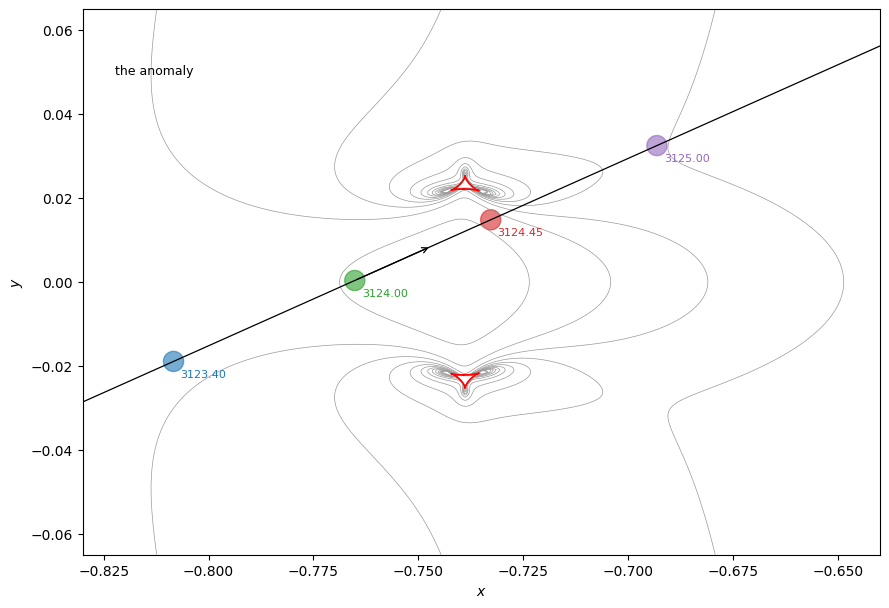

In [14]:
figures.plot_geometry([best], labels=["whole system"], ncols=1, figsize=(8, 5.6), extent=(-1.0, 0.85, -0.6, 0.6),
                      t_arrow=3132.0)
plt.gca().add_patch(plt.Rectangle((-0.83, -0.065), 0.19, 0.13, fill=False, ec="k", lw=0.8))
fig = figures.plot_geometry([best], labels=["the anomaly"], ncols=1, figsize=(9, 6.5),
                            extent=(-0.83, -0.64, -0.065, 0.065), t_arrow=3124.0, levels=np.geomspace(0.5, 3, 30))
ax = fig.axes[0]
x0 = caustics.lens_positions(10 ** best[3], 10 ** best[4])[0]
rho = 10 ** best[6]
for t, c in ((3123.4, "C0"), (3124.0, "C2"), (3124.45, "C3"), (3125.0, "C4")):
    z = caustics.trajectory(best, [t])[0]
    ax.add_patch(plt.Circle((z.real - x0, z.imag), rho, color=c, alpha=0.6))
    ax.annotate(f"{t:.2f}", (z.real - x0, z.imag), xytext=(5, -11), textcoords="offset points", fontsize=8, color=c)

Coordinates are in Einstein radii, centred on the host star; the planet (the blue dot on the right, at *x* = 0.70) lies
on the other side of the host from the source's anomaly. A close planet (*s* < 1) splits its planetary caustic into
two small triangles, here at *x* ≈ −0.74, *y* ≈ ±0.023, on the opposite side of the host from the planet; between
them is a region where the source is *demagnified*. The tiny central caustic sits at the host.

The right panel follows the source (circles of radius ρ at the BJD′ marked) through the anomaly. It enters the region
between the triangles, which makes the dip (BJD′ 3123.4–3124.4), crosses the binary axis at BJD′ 3124.0 and then passes
the cusp of the upper triangle (BJD′ 3124.45, closest approach 3.1 source radii from the caustic), which makes the
sharp rise. It does not cross the caustic. Even at three source radii the finite size of the source smooths the
rise measurably at Roman's precision; this is why ρ is measured at all.

## 10. What kind of system is this?

**What the light curve measures directly.**

* The planet has *q* = 1.16 × 10⁻⁴ of its host's mass: about 40 times the Earth–Sun ratio (3.0 × 10⁻⁶), twice the
  Neptune–Sun ratio (5.1 × 10⁻⁵) and an eighth of the Jupiter–Sun ratio (9.5 × 10⁻⁴).
* Its projected separation is *s* = 0.697 Einstein radii, inside the Einstein ring. The close solution is preferred to
  the wide one (s ≈ 1.43) by Δχ² ≈ 10 600, so the usual close/wide ambiguity of planetary caustics does not arise:
  the dip between the two triangles has no counterpart in the wide geometry.
* The Einstein timescale is *t*ₑ = 12.7 d, and the source takes *t*⋆ = ρ *t*ₑ = 44 minutes to cross its own radius.

**Physical scale (rough).** Masses and distances need the angular Einstein radius θₑ = θ⋆/ρ and the parallax, which
this static fit does not include. A first estimate of θ⋆ comes from the source's brightness:

* The fit gives source magnitudes F087 = 21.42, F146 = 20.52, F213 = 20.52. The challenge lists the extinction along
  the line of sight (*A* = 1.45, 0.58, 0.19 mag); without it the source is F146₀ = 19.94 with (F087 − F213)₀ = −0.36.
* If the source is in the bulge (8 kpc, distance modulus 14.5) and the magnitudes are AB magnitudes, its absolute F146
  magnitude is 5.4, about 0.7 mag fainter than the Sun in the H band (*H*_AB ≈ 4.7). With the Sun's surface brightness
  in the near infrared (which changes slowly with temperature), that is a star of about 0.7 solar radii, a K dwarf,
  with θ⋆ ≈ 0.4 µas.
* Then θₑ = θ⋆/ρ ≈ 0.17 mas and μ = θₑ/*t*ₑ ≈ 5 mas/yr, a typical value for the bulge.

With θₑ² = κ *M* π_rel (κ = 8.14 mas/M_⊙, π_rel = 1/D_L − 1/D_S in mas with distances in kpc), this θₑ fixes *M* × π_rel
but not the two separately:

In [15]:
theta_E = 0.40e-3 / 10 ** best[6]          # mas, from theta_* ~ 0.4 micro-arcsec (rough, see text)
DS = 8.0
print(f"theta_E = {theta_E:.3f} mas, mu_rel = {theta_E / best[2] * 365.25:.1f} mas/yr")
print(f"{'D_L (kpc)':>9s} {'M_host (Msun)':>13s} {'M_planet (Earth)':>16s} {'a_perp (AU)':>11s}")
for DL in (3.0, 5.0, 6.0, 7.0):
    pirel = 1 / DL - 1 / DS
    M = theta_E ** 2 / (8.144 * pirel)
    print(f"{DL:9.1f} {M:13.3f} {10 ** best[4] * M * 332946:16.1f} {10 ** best[3] * theta_E * DL:11.2f}")

theta_E = 0.167 mas, mu_rel = 4.8 mas/yr
D_L (kpc) M_host (Msun) M_planet (Earth) a_perp (AU)
      3.0         0.016              0.6        0.35
      5.0         0.045              1.7        0.58
      6.0         0.082              3.1        0.70
      7.0         0.191              7.3        0.81


For any lens distance between 3 and 7 kpc the host is a low-mass star or brown dwarf (0.02–0.2 M_⊙) and the planet has
the mass of a few Earths, about 0.6 to 7 Earth masses for those hosts, at a projected separation of 0.35–0.8 AU. A
host near the bulge (*D*_L ≈ 6–7 kpc) is most likely; then this is a **super-Earth or mini-Neptune of 3–7 Earth
masses orbiting an M dwarf at 0.7–0.8 AU**, beyond its snow line, the kind of planet Roman's survey is designed
to find in large numbers.

These numbers rest on assumptions, all of which can be removed in a full analysis: the magnitude system of the
challenge (if Vega instead of AB, θ⋆ grows by about 1.9 and every mass by 3.6), the Sun's surface brightness, the source
distance, and the missing parallax. Roman's orbit and the Earth's motion over 4.7 years give a parallax signal, but
a Bayesian analysis with a Galactic model would still be needed.

## 11. Summary

* A blind 2L1S analysis of a simulated Roman event finds one solution: a close planet with *q* = 1.16 × 10⁻⁴ and
  *s* = 0.697, which fits all 49 096 points to χ²/N = 1.0003. No other minimum is within Δχ² = 1000 on the map; the wide
  alternative is 10 600 worse.
* Reducing the data to the event's season, and binning outside the anomaly, cut the points from 49 096 to 1773 and the
  time of a χ² by about 340 times, without changing any Δχ² between models by more than 1 in 10 000. All maps together took
  24 minutes on a desktop.
* Roman's precision makes the valley tiny: Δχ² < 4 spans 0.0012 dex in log *s*. A map with steps typical for
  ground-based events misses the floor by 47, so zoom boxes (here 8× and 64×) are needed to resolve it.
* Not done yet: parallax (which needs all six seasons), uncertainties (MCMC), limb darkening, and a physical
  analysis beyond the rough scale above.

**References.** Gaudi, B. S. 2012, ARA&A, 50, 411. Penny, M. T., et al. 2019, ApJS, 241, 3. Roman Microlensing Data
Challenge 2026, RGES-PIT, [rges-pit.org/data-challenge](https://rges-pit.org/data-challenge/).